In [7]:
from itertools import product


def cell_index(x: int, y: int, z: int) -> int:
    return 9 * z + 3 * y + x


def generate_lines(allow_decreasing: bool) -> list[tuple[int, int, int]]:
    """Generate all unique 3-cell lines in {0, 1, 2}^3."""
    rules = [("const", 0), ("const", 1), ("const", 2), ("inc", 0)]
    if allow_decreasing:
        rules.append(("dec", 0))

    lines = set()
    for rx, ry, rz in product(rules, repeat=3):
        # Skip degenerate points where all 3 coordinates stay constant
        if rx[0] == "const" and ry[0] == "const" and rz[0] == "const":
            continue

        pts = []
        for t in range(3):
            coords = []
            for kind, val in (rx, ry, rz):
                if kind == "const":
                    coords.append(val)
                elif kind == "inc":
                    coords.append(t)
                else:  # "dec"
                    coords.append(2 - t)
            pts.append(cell_index(*coords))

        lines.add(tuple(sorted(pts)))

    return sorted(lines)


def count_valid_colorings(lines: list[tuple[int, int, int]]) -> tuple[int, list[int] | None]:
    """Count all 2-colorings with no monochromatic line via pruned backtracking."""
    # Bucket each line by its highest-indexed cell so we prune immediately
    lines_ending_at: list[list[tuple[int, int]]] = [[] for _ in range(27)]
    for a, b, c in lines:
        lines_ending_at[c].append((a, b))

    colors = [-1] * 27
    sample_coloring: list[int] | None = None

    def backtrack(pos: int) -> int:
        nonlocal sample_coloring
        if pos == 27:
            if sample_coloring is None:
                sample_coloring = colors.copy()
            return 1

        total = 0
        for col in (0, 1):
            # Check only lines whose 3rd cell is `pos`
            if all(not (colors[a] == col and colors[b] == col) for a, b in lines_ending_at[pos]):
                colors[pos] = col
                total += backtrack(pos + 1)
        colors[pos] = -1
        return total

    # Fix cell 0 to color 0 by symmetry and multiply the final count by 2
    colors[0] = 0
    valid_count = 2 * backtrack(1)
    return valid_count, sample_coloring


def print_cube(coloring: list[int]) -> None:
    symbols = {0: "R", 1: "B"}
    for y in reversed(range(3)):  # Top row to bottom row
        row_str = []
        for z in range(3):  # Left square to right square
            layer_row = " ".join(symbols[coloring[cell_index(x, y, z)]] for x in range(3))
            row_str.append(layer_row)
        print("   |   ".join(row_str))



# 1. Geometric lines (standard 3D Tic-Tac-Toe)
geom_lines = generate_lines(allow_decreasing=True)
geom_count, _ = count_valid_colorings(geom_lines)
print(f"Geometric lines total:     {len(geom_lines)}")
print(f"Valid geometric colorings: {geom_count}\n")

# 2. Combinatorial lines (Hales-Jewett)
comb_lines = generate_lines(allow_decreasing=False)
comb_count, example = count_valid_colorings(comb_lines)
print(f"Combinatorial lines total:     {len(comb_lines)}")
print(f"Valid combinatorial colorings: {comb_count}")

if example:
    print("\nExample valid combinatorial 2-coloring (slices z=1, z=2, z=3):")
    print_cube(example)

Geometric lines total:     49
Valid geometric colorings: 0

Combinatorial lines total:     37
Valid combinatorial colorings: 1644

Example valid combinatorial 2-coloring (slices z=1, z=2, z=3):
B R R   |   R R B   |   R B B
R B R   |   B R R   |   R R B
R R B   |   R B R   |   B R R


In [1]:
!pip install -q python-sat

In [4]:
# Run this line in a Colab cell first:
# !pip install -q python-sat

import time
import threading
from itertools import product
from pysat.solvers import Solver


def generate_lines(n: int, d: int, allow_decreasing: bool) -> list[tuple[int, ...]]:
    """Generate all 1-indexed variable clauses for lines in [n]^d."""
    rules = [("const", c) for c in range(n)] + [("inc", 0)]
    if allow_decreasing:
        rules.append(("dec", 0))

    # Precompute powers of n for fast base-n flattening
    powers = [n ** i for i in range(d)]
    lines = set()

    for rule_tuple in product(rules, repeat=d):
        if all(kind == "const" for kind, _ in rule_tuple):
            continue

        pts = []
        for t in range(n):
            idx = 1  # 1-indexed SAT variables
            for dim, (kind, val) in enumerate(rule_tuple):
                if kind == "const":
                    coord = val
                elif kind == "inc":
                    coord = t
                else:  # "dec"
                    coord = n - 1 - t
                idx += coord * powers[dim]
            pts.append(idx)

        lines.add(tuple(sorted(pts)))

    return list(lines)


def check_dimension(n: int, d: int, allow_decreasing: bool, timeout_sec: float = 10.0) -> tuple[str, float, int, int]:
    """
    Test if a valid 2-coloring exists for [n]^d.
    Returns (status, elapsed_seconds, num_cells, num_lines):
      - 'SAT'     -> valid coloring exists (cutoff > d)
      - 'UNSAT'   -> no valid coloring exists (cutoff <= d)
      - 'TIMEOUT' -> solver exceeded timeout_sec
    """
    t0 = time.perf_counter()
    num_cells = n ** d
    lines = generate_lines(n, d, allow_decreasing)

    with Solver(name="g4") as solver:
        # Symmetry breaking 1: fix cell (0, 0, ..., 0) to True (color 1)
        solver.add_clause([1])

        # Symmetry breaking 2: sort unit-axis points e_1 >= e_2 >= ... >= e_d
        # Breaks all d! coordinate-permutation symmetries cleanly
        if d >= 2:
            axis_vars = [1 + (n ** i) for i in range(d)]
            for i in range(d - 1):
                solver.add_clause([axis_vars[i], -axis_vars[i + 1]])

        # Forbid monochromatic lines (all True or all False)
        for line in lines:
            solver.add_clause([-v for v in line])  # Not all Red
            solver.add_clause([v for v in line])   # Not all Blue

        timer = threading.Timer(timeout_sec, solver.interrupt)
        timer.start()
        try:
            result = solver.solve_limited(expect_interrupt=True)
        finally:
            timer.cancel()

    elapsed = time.perf_counter() - t0
    if result is True:
        status = "SAT"
    elif result is False:
        status = "UNSAT"
    else:
        status = "TIMEOUT"

    return status, elapsed, num_cells, len(lines)


def study_cutoffs(
    n_values: tuple[int, ...] = (3, 4, 5, 6, 7),
    max_cells: int = 2500,
    timeout_sec: float = 10.0,
) -> None:
    print(f"{'n':>2} | {'Mode':<13} | {'d':>2} | {'Cells':>6} | {'Lines':>7} | {'Status':<7} | {'Time (s)':>8}")
    print("-" * 62)

    for n in n_values:
        for mode_name, allow_dec in [("Geometric", True), ("Combinatorial", False)]:
            d = 2
            while n ** d <= max_cells:
                status, elapsed, cells, num_lines = check_dimension(
                    n, d, allow_decreasing=allow_dec, timeout_sec=timeout_sec
                )
                print(
                    f"{n:>2} | {mode_name:<13} | {d:>2} | {cells:>6} | {num_lines:>7} | "
                    f"{status:<7} | {elapsed:>8.3f}"
                )

                # Stop once we prove UNSAT (exact cutoff found!) or hit timeout
                if status in ("UNSAT", "TIMEOUT"):
                    break
                d += 1
        print("-" * 62)


if __name__ == "__main__":
    # Increase timeout_sec (e.g. 60.0) and max_cells (e.g. 5000) on Colab for deeper lower bounds
    study_cutoffs(n_values=(3, 4, 5, 6, 7), max_cells=100000, timeout_sec=300.0)

 n | Mode          |  d |  Cells |   Lines | Status  | Time (s)
--------------------------------------------------------------
 3 | Geometric     |  2 |      9 |       8 | SAT     |    0.001
 3 | Geometric     |  3 |     27 |      49 | UNSAT   |    0.003
 3 | Combinatorial |  2 |      9 |       7 | SAT     |    0.001
 3 | Combinatorial |  3 |     27 |      37 | SAT     |    0.001
 3 | Combinatorial |  4 |     81 |     175 | UNSAT   |    0.001
--------------------------------------------------------------
 4 | Geometric     |  2 |     16 |      10 | SAT     |    0.000
 4 | Geometric     |  3 |     64 |      76 | SAT     |    0.001
 4 | Geometric     |  4 |    256 |     520 | SAT     |    0.006
 4 | Geometric     |  5 |   1024 |    3376 | TIMEOUT |  300.052
 4 | Combinatorial |  2 |     16 |       9 | SAT     |    0.001
 4 | Combinatorial |  3 |     64 |      61 | SAT     |    0.001
 4 | Combinatorial |  4 |    256 |     369 | SAT     |    0.003
 4 | Combinatorial |  5 |   1024 |    2101

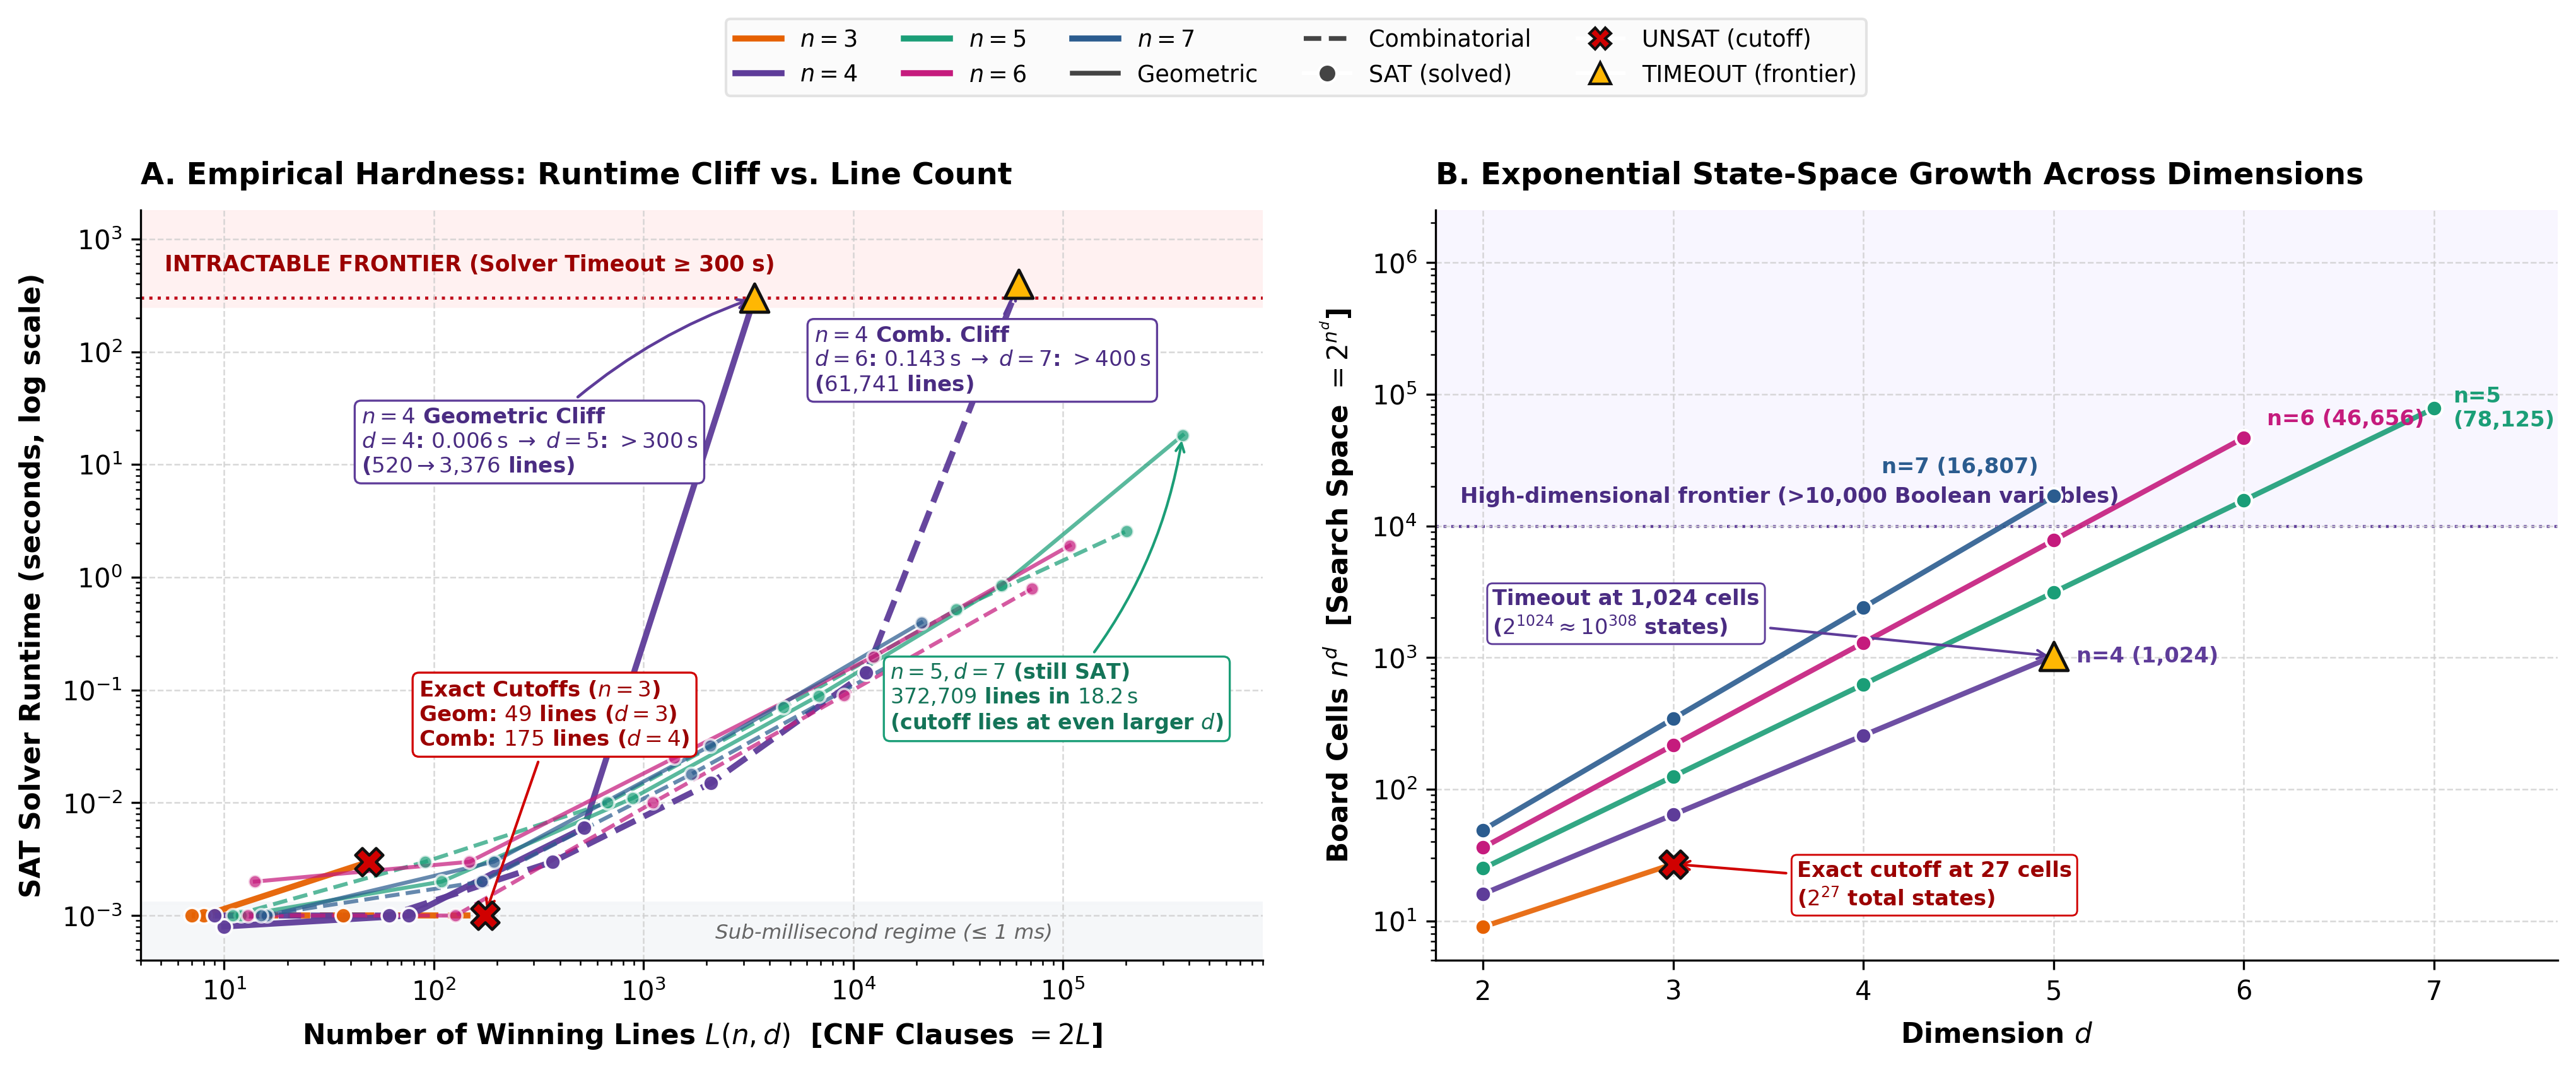

In [6]:
import io
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

raw_data = """
n | Mode | d | Cells | Lines | Status | Time
3 | Geometric | 2 | 9 | 8 | SAT | 0.001
3 | Geometric | 3 | 27 | 49 | UNSAT | 0.003
3 | Combinatorial | 2 | 9 | 7 | SAT | 0.001
3 | Combinatorial | 3 | 27 | 37 | SAT | 0.001
3 | Combinatorial | 4 | 81 | 175 | UNSAT | 0.001
4 | Geometric | 2 | 16 | 10 | SAT | 0.000
4 | Geometric | 3 | 64 | 76 | SAT | 0.001
4 | Geometric | 4 | 256 | 520 | SAT | 0.006
4 | Geometric | 5 | 1024 | 3376 | TIMEOUT | 300.052
4 | Combinatorial | 2 | 16 | 9 | SAT | 0.001
4 | Combinatorial | 3 | 64 | 61 | SAT | 0.001
4 | Combinatorial | 4 | 256 | 369 | SAT | 0.003
4 | Combinatorial | 5 | 1024 | 2101 | SAT | 0.015
4 | Combinatorial | 6 | 4096 | 11529 | SAT | 0.143
4 | Combinatorial | 7 | 16384 | 61741 | TIMEOUT | 399.782
5 | Geometric | 2 | 25 | 12 | SAT | 0.001
5 | Geometric | 3 | 125 | 109 | SAT | 0.002
5 | Geometric | 4 | 625 | 888 | SAT | 0.011
5 | Geometric | 5 | 3125 | 6841 | SAT | 0.089
5 | Geometric | 6 | 15625 | 51012 | SAT | 0.845
5 | Geometric | 7 | 78125 | 372709 | SAT | 18.219
5 | Combinatorial | 2 | 25 | 11 | SAT | 0.001
5 | Combinatorial | 3 | 125 | 91 | SAT | 0.003
5 | Combinatorial | 4 | 625 | 671 | SAT | 0.010
5 | Combinatorial | 5 | 3125 | 4651 | SAT | 0.070
5 | Combinatorial | 6 | 15625 | 31031 | SAT | 0.516
5 | Combinatorial | 7 | 78125 | 201811 | SAT | 2.571
6 | Geometric | 2 | 36 | 14 | SAT | 0.002
6 | Geometric | 3 | 216 | 148 | SAT | 0.003
6 | Geometric | 4 | 1296 | 1400 | SAT | 0.025
6 | Geometric | 5 | 7776 | 12496 | SAT | 0.198
6 | Geometric | 6 | 46656 | 107744 | SAT | 1.912
6 | Combinatorial | 2 | 36 | 13 | SAT | 0.001
6 | Combinatorial | 3 | 216 | 127 | SAT | 0.001
6 | Combinatorial | 4 | 1296 | 1105 | SAT | 0.010
6 | Combinatorial | 5 | 7776 | 9031 | SAT | 0.090
6 | Combinatorial | 6 | 46656 | 70993 | SAT | 0.789
7 | Geometric | 2 | 49 | 16 | SAT | 0.001
7 | Geometric | 3 | 343 | 193 | SAT | 0.003
7 | Geometric | 4 | 2401 | 2080 | SAT | 0.032
7 | Geometric | 5 | 16807 | 21121 | SAT | 0.397
7 | Combinatorial | 2 | 49 | 15 | SAT | 0.001
7 | Combinatorial | 3 | 343 | 169 | SAT | 0.002
7 | Combinatorial | 4 | 2401 | 1695 | SAT | 0.018
7 | Combinatorial | 5 | 16807 | 15961 | SAT | 0.177
"""

df = pd.read_csv(io.StringIO(raw_data.strip()), sep=r"\s*\|\s*", engine="python")
df["Time_Plot"] = df["Time"].clip(lower=0.0008)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13.8, 5.5), dpi=300)
fig.patch.set_facecolor("white")

palette = {3: "#E66101", 4: "#5E3C99", 5: "#1B9E77", 6: "#C51B7D", 7: "#2B5C8F"}

# Panel A: Empirical Hardness (Runtime vs. Line Count)
ax1.set_xscale("log")
ax1.set_yscale("log")
ax1.set_xlim(4, 9e5)
ax1.set_ylim(4e-4, 1.8e3)

ax1.axhspan(250, 1.8e3, color="#FFF0F0", alpha=0.9, zorder=0)
ax1.axhline(300, color="#C1121F", linestyle=":", linewidth=1.2, zorder=1)
ax1.text(5.2, 520, "INTRACTABLE FRONTIER (Solver Timeout ≥ 300 s)",
         fontsize=8.3, fontweight="bold", color="#9B0000")

ax1.axhspan(4e-4, 1.3e-3, color="#F4F6F8", alpha=0.85, zorder=0)
ax1.text(2.2e3, 6.2e-4, "Sub-millisecond regime (≤ 1 ms)",
         fontsize=7.8, color="#666666", style="italic")

for n_val in [3, 4, 5, 6, 7]:
    col = palette[n_val]
    for mode, ls in [("Geometric", "-"), ("Combinatorial", "--")]:
        sub = df[(df["n"] == n_val) & (df["Mode"] == mode)].sort_values("Lines")
        lw = 2.3 if n_val in (3, 4) else 1.5
        alpha = 0.95 if n_val in (3, 4) else 0.72
        ax1.plot(sub["Lines"], sub["Time_Plot"], linestyle=ls, linewidth=lw, color=col, alpha=alpha, zorder=2)

        for _, r in sub.iterrows():
            if r["Status"] == "SAT":
                ax1.scatter(r["Lines"], r["Time_Plot"], s=36 if n_val in (3, 4) else 26,
                            facecolor=col, edgecolor="white", linewidth=0.9, alpha=alpha, zorder=3)
            elif r["Status"] == "UNSAT":
                ax1.scatter(r["Lines"], r["Time_Plot"], marker="X", s=110,
                            facecolor="#D00000", edgecolor="#111111", linewidth=1.1, zorder=5)
            elif r["Status"] == "TIMEOUT":
                ax1.scatter(r["Lines"], r["Time_Plot"], marker="^", s=115,
                            facecolor="#FFB703", edgecolor="#111111", linewidth=1.2, zorder=5)

ax1.annotate("Exact Cutoffs ($n=3$)\nGeom: $49$ lines ($d=3$)\nComb: $175$ lines ($d=4$)",
             xy=(175, 0.001), xytext=(85, 0.032),
             fontsize=8.2, fontweight="bold", color="#9B0000",
             bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="#D00000", lw=0.8),
             arrowprops=dict(arrowstyle="->", color="#D00000", lw=1.0))

ax1.annotate("$n=4$ Geometric Cliff\n$d=4$: $0.006\\,\\mathrm{s} \\;\\to\\; d=5$: $>300\\,\\mathrm{s}$\n($520 \\to 3{,}376$ lines)",
             xy=(3376, 300.052), xytext=(45, 8.5),
             fontsize=8.2, fontweight="bold", color="#4A2C82",
             bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="#5E3C99", lw=0.8),
             arrowprops=dict(arrowstyle="->", color="#5E3C99", lw=1.1, connectionstyle="arc3,rad=-0.12"))

ax1.annotate("$n=4$ Comb. Cliff\n$d=6$: $0.143\\,\\mathrm{s} \\;\\to\\; d=7$: $>400\\,\\mathrm{s}$\n($61{,}741$ lines)",
             xy=(61741, 399.782), xytext=(6.5e3, 45),
             fontsize=8.2, fontweight="bold", color="#4A2C82",
             bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="#5E3C99", lw=0.8),
             arrowprops=dict(arrowstyle="->", color="#5E3C99", lw=1.1))

ax1.annotate("$n=5, d=7$ (still SAT)\n$372{,}709$ lines in $18.2\\,\\mathrm{s}$\n(cutoff lies at even larger $d$)",
             xy=(372709, 18.219), xytext=(1.5e4, 0.045),
             fontsize=8.0, color="#147458", fontweight="bold",
             bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="#1B9E77", lw=0.8),
             arrowprops=dict(arrowstyle="->", color="#1B9E77", lw=1.0, connectionstyle="arc3,rad=0.15"))

ax1.grid(True, which="major", linestyle="--", linewidth=0.6, color="#D0D0D0", alpha=0.85)
ax1.spines["top"].set_visible(False)
ax1.spines["right"].set_visible(False)
ax1.set_xlabel("Number of Winning Lines $L(n, d)$  [CNF Clauses $= 2L$]", fontsize=10.5, fontweight="bold", labelpad=6)
ax1.set_ylabel("SAT Solver Runtime (seconds, log scale)", fontsize=10.5, fontweight="bold", labelpad=6)
ax1.set_title("A. Empirical Hardness: Runtime Cliff vs. Line Count", fontsize=11.5, fontweight="bold", loc="left", pad=10)

# Panel B: State-Space Growth (Variables n^d vs. Dimension d)
ax2.set_yscale("log")
ax2.set_xlim(1.75, 7.65)
ax2.set_ylim(5, 2.5e6)

ax2.axhspan(1e4, 2.5e6, color="#F8F5FF", alpha=0.9, zorder=0)
ax2.axhline(1e4, color="#5E3C99", linestyle=":", linewidth=1.1, zorder=1)
ax2.text(1.88, 1.5e4, "High-dimensional frontier (>10,000 Boolean variables)",
         fontsize=8.1, fontweight="bold", color="#4A2C82")

for n_val in [3, 4, 5, 6, 7]:
    col = palette[n_val]
    sub = df[(df["n"] == n_val) & (df["Mode"] == "Geometric")].sort_values("d")
    ax2.plot(sub["d"], sub["Cells"], linestyle="-", linewidth=2.0, color=col, alpha=0.9, zorder=2)

    for _, r in sub.iterrows():
        if r["Status"] == "UNSAT":
            ax2.scatter(r["d"], r["Cells"], marker="X", s=110, facecolor="#D00000", edgecolor="#111111", linewidth=1.1, zorder=5)
        elif r["Status"] == "TIMEOUT":
            ax2.scatter(r["d"], r["Cells"], marker="^", s=115, facecolor="#FFB703", edgecolor="#111111", linewidth=1.2, zorder=5)
        else:
            ax2.scatter(r["d"], r["Cells"], s=38, facecolor=col, edgecolor="white", linewidth=1.0, zorder=4)

ax2.text(7.1, 78125, "n=5\n(78,125)", fontsize=8.1, fontweight="bold", color=palette[5], va="center")
ax2.text(6.12, 46656 * 1.15, "n=6 (46,656)", fontsize=8.1, fontweight="bold", color=palette[6], va="bottom")
ax2.text(4.92, 16807 * 1.38, "n=7 (16,807)", fontsize=8.1, fontweight="bold", color=palette[7], ha="right", va="bottom")
ax2.text(5.12, 1024, "n=4 (1,024)", fontsize=8.1, fontweight="bold", color=palette[4], va="center")

ax2.annotate("Exact cutoff at 27 cells\n($2^{27}$ total states)", xy=(3, 27), xytext=(3.65, 13),
             fontsize=8.1, fontweight="bold", color="#9B0000",
             bbox=dict(boxstyle="round,pad=0.25", fc="white", ec="#D00000", lw=0.7),
             arrowprops=dict(arrowstyle="->", color="#D00000", lw=1.0))

ax2.annotate("Timeout at 1,024 cells\n($2^{1024} \\approx 10^{308}$ states)", xy=(5, 1024), xytext=(2.05, 1500),
             fontsize=8.1, fontweight="bold", color="#4A2C82",
             bbox=dict(boxstyle="round,pad=0.25", fc="white", ec="#5E3C99", lw=0.7),
             arrowprops=dict(arrowstyle="->", color="#5E3C99", lw=1.0))

ax2.grid(True, which="major", linestyle="--", linewidth=0.6, color="#D0D0D0", alpha=0.85)
ax2.spines["top"].set_visible(False)
ax2.spines["right"].set_visible(False)
ax2.set_xticks([2, 3, 4, 5, 6, 7])
ax2.set_xlabel("Dimension $d$", fontsize=10.5, fontweight="bold", labelpad=6)
ax2.set_ylabel("Board Cells $n^d$  [Search Space $= 2^{n^d}$]", fontsize=10.5, fontweight="bold", labelpad=6)
ax2.set_title("B. Exponential State-Space Growth Across Dimensions", fontsize=11.5, fontweight="bold", loc="left", pad=10)

legend_handles = [
    Line2D([0], [0], color=palette[3], lw=2.3, label="$n = 3$"),
    Line2D([0], [0], color=palette[4], lw=2.3, label="$n = 4$"),
    Line2D([0], [0], color=palette[5], lw=2.3, label="$n = 5$"),
    Line2D([0], [0], color=palette[6], lw=2.3, label="$n = 6$"),
    Line2D([0], [0], color=palette[7], lw=2.3, label="$n = 7$"),
    Line2D([0], [0], color="#444444", lw=1.8, linestyle="-", label="Geometric"),
    Line2D([0], [0], color="#444444", lw=1.8, linestyle="--", label="Combinatorial"),
    Line2D([0], [0], marker="o", color="w", markerfacecolor="#444444", markersize=7, label="SAT (solved)"),
    Line2D([0], [0], marker="X", color="w", markerfacecolor="#D00000", markeredgecolor="#111", markersize=8, label="UNSAT (cutoff)"),
    Line2D([0], [0], marker="^", color="w", markerfacecolor="#FFB703", markeredgecolor="#111", markersize=8, label="TIMEOUT (frontier)"),
]

fig.legend(handles=legend_handles, loc="upper center", bbox_to_anchor=(0.5, 1.03),
           ncol=5, frameon=True, facecolor="#FAFAFA", edgecolor="#DDDDDD", fontsize=8.8)

plt.tight_layout(rect=[0, 0, 1, 0.91])
plt.savefig("hj_hardness_clean.png", dpi=300, bbox_inches="tight")
plt.savefig("hj_hardness_clean.pdf", bbox_inches="tight")
plt.show()